# 10 · Sessions that never reach the till: cancellations, cancel-and-walk, dead handsets (v1.3)

Everything up to v1.1 assumed every SmartShop session ends at the till barcode, where the rescan
decision is made. In store, some never get there:

- **Genuine cancellation.** A shopper scans a few items (or most of them), gets an urgent call or
  can't find what they came for, cancels SmartShop and leaves the items. Nothing is lost.
- **Cancel-and-walk.** A shoplifter scans items so the session looks normal, cancels, pays
  nothing, and leaves through the self-scan gates behind a customer who has scanned their receipt
  barcode to open them, which is easier when it is busy. **The whole basket is lost, and no rescan
  ever sees it.**
- **Dead device.** The store's handset (or the shopper's phone) dies part-way. Today the customer
  has to scan everything again on another handset, at self-scan or at a checkout. A handset is the
  store's equipment, so that is the store's failure, not the customer's.

Genuine cancellations and cancel-and-walk can both happen early or late in a shop, so timing does
not tell them apart. Any response has to be one that is right for both.

**v1.3:**

| | Today | v1.3 |
|---|---|---|
| Cancelled with items scanned | Nothing happens | A colleague near the exit gets a prompt to **help** (take the basket back, find the item, show the way to a till); every cancellation, or only the higher-risk ones when colleagues are stretched |
| Handset or phone dies | Customer rescans everything | **Resume** on another handset or at a till from the Nectar card; never a risk signal |
| Handsets handed out | Whichever the customer grabs | **Longest on the rack first**, and handsets that keep dying sent for a new battery, from the handset log alone (the handsets show no battery level) |

No published figures exist for any of these rates, so every one is a stated assumption (in
`policy/exits.py` and `ops/handsets.py`) and eight other worlds vary them. Produced by
`python -m smartshop.reporting.exits`; this notebook reads its outputs.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from smartshop.viz import BLUE, GREY, ORANGE, TEXT_2, money, pct, save, set_style, subtitle

set_style()
t = pd.read_csv('../models/exits.csv')
hs = pd.read_csv('../models/handsets.csv')
fair = pd.read_csv('../models/exits_fairness.csv')
summ = json.load(open('../models/exits_summary.json'))
print(f"cancel-and-walk today: ${summ['walk_out_loss_today']:,.0f}, "
      f"{summ['walk_out_share_of_all_loss_today']:.0%} of all loss, invisible to rescans")

cancel-and-walk today: $5,810, 12% of all loss, invisible to rescans


## 1. Dead handsets: hand out the right one

In [2]:
hs[['policy', 'sessions', 'failures', 'failures per 1,000 sessions', 'min', 'max',
    'mean point of failure (share of shop)']].round(2)

,policy,sessions,failures,"failures per 1,000 sessions",min,max,mean point of failure (share of shop)
0,random,20433,131,6.41,0.88,12.58,0.60
1,longest on rack first,20433,86,4.21,0.59,8.27,0.75
2,+ retire,20433,10,0.49,0.15,0.88,0.86


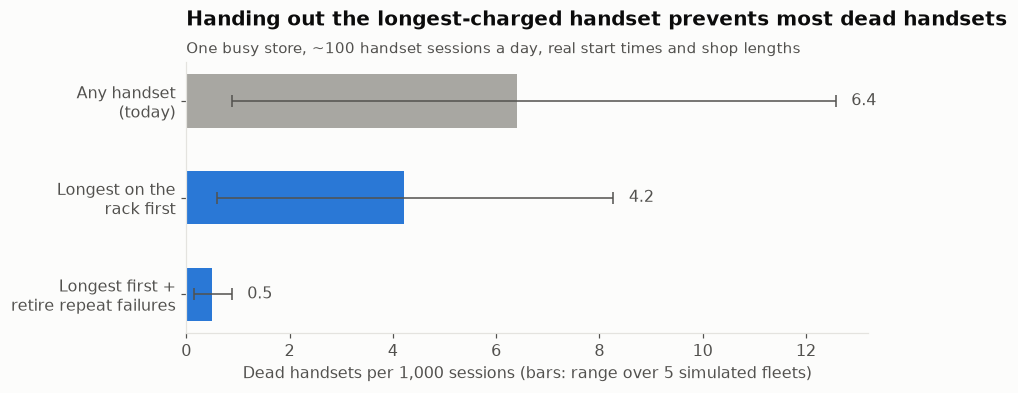

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.2))
labels = ['Any handset\n(today)', 'Longest on the\nrack first', 'Longest first +\nretire repeat failures']
v = hs['failures per 1,000 sessions']
bars = ax.barh(labels, v, color=[GREY, BLUE, BLUE], height=0.55)
ax.errorbar(v, range(len(v)), xerr=[v - hs['min'], hs['max'] - v], fmt='none', ecolor=TEXT_2,
            capsize=4, lw=1)
for i, (x, hi) in enumerate(zip(v, hs['max'])):
    ax.text(hi + 0.3, i, f'{x:.1f}', va='center', color=TEXT_2)
ax.invert_yaxis()
ax.set_xlabel('Dead handsets per 1,000 sessions (bars: range over 5 simulated fleets)')
ax.grid(axis='y', visible=False)
ax.set_title('Handing out the longest-charged handset prevents most dead handsets')
subtitle(ax, 'One busy store, ~100 handset sessions a day, real start times and shop lengths')
save(fig, '24_dead_handsets')
fig

The handsets show no battery level, so the store cannot choose by charge. But it knows which
handset each session used and when it went back on the rack. **Handing out the handset that has
been charging longest** avoids most deaths of handsets put back half-empty, and **sending
handsets that die twice in a month for a new battery** removes the worn ones. Together dead
handsets fall by 92% in this fleet and by 72–93% across five other simulated fleets. When one still dies, v1.3 resumes the session
instead of making the customer rescan everything.

## 2. Cancellations and cancel-and-walk

In [4]:
base = t[t.world == 'Base assumptions'].set_index('arm')
rows = ['walk-out attempts', 'walk-outs', 'walk-out loss', 'stopped by a colleague', 'prompts',
        'prompts answered', 'prompts that were walk-outs', 'genuine cancellers helped',
        'colleague hours on prompts', 'dead handsets', 'customer hours lost to dead devices',
        'colleague hours on dead devices']
base[rows].T.round(1)

arm,Today,v1.3: help every cancellation,v1.3: help higher-risk
walk-out attempts,163.2,163.2,163.2
walk-outs,131.7,72.3,91.0
walk-out loss,5810.3,2972.8,3536.1
stopped by a colleague,0.0,74.6,50.5
prompts,0.0,1282.7,723.0
prompts answered,0.0,896.0,503.5
prompts that were walk-outs,0.0,93.6,63.6
genuine cancellers helped,0.0,802.4,439.8
colleague hours on prompts,0.0,14.9,8.4
dead handsets,119.7,9.4,9.4


In [5]:
today = t[t.arm == 'Today'].set_index('world')
t['walk-out loss vs today'] = t['walk-out loss'] / t.world.map(today['walk-out loss']) - 1
t['net colleague hours'] = (t['colleague hours on prompts'] + t['colleague hours on dead devices']
                            - t.world.map(today['colleague hours on dead devices']))
t['$ saved per net colleague hour'] = ((t.world.map(today['walk-out loss']) - t['walk-out loss'])
                                       / t['net colleague hours'])
t['prompts that were walk-outs (share)'] = t['prompts that were walk-outs'] / t['prompts answered']
v13 = t[t.arm != 'Today']
v13.pivot(index='world', columns='arm', values=['walk-out loss vs today', '$ saved per net colleague hour',
                                                'prompts that were walk-outs (share)']).round(2)

walk-out loss vs today  \
arm                                   v1.3: help every cancellation   
world                                                                 
Base assumptions                                              -0.49   
Colleagues stretched (free 40% / 30%)                         -0.25   
Fewer genuine cancellations (1%)                              -0.49   
Gates flag two people per receipt                             -0.48   
Half as many walk-outs                                        -0.50   
Harder to tailgate (50% / 70%)                                -0.50   
More genuine cancellations (6%)                               -0.49   
Prompts only for the top 25%                                  -0.49   
Twice as many walk-outs                                       -0.49   

                                                              \
arm                                   v1.3: help higher-risk   
world                                                          
Base assumptions                                       -0.39   
Colleagues stretched (free 40% / 30%)                  -0.20   
Fewer genuine cancellations (1%)                       -0.39   
Gates flag two people per receipt                      -0.39   
Half as many walk-outs                                 -0.40   
Harder to tailgate (50% / 70%)                         -0.40   
More genuine cancellations (6%)                        -0.39   
Prompts only for the top 25%                           -0.28   
Twice as many walk-outs                                -0.39   

                                      $ saved per net colleague hour  \
arm                                    v1.3: help every cancellation   
world                                                                  
Base assumptions                                              238.25   
Colleagues stretched (free 40% / 30%)                         321.69   
Fewer genuine cancellations (1%)                              982.68   
Gates flag two people per receipt                             177.28   
Half as many walk-outs                                        129.10   
Harder to tailgate (50% / 70%)                                182.29   
More genuine cancellations (6%)                               110.92   
Prompts only for the top 25%                                  238.25   
Twice as many walk-outs                                       429.09   

                                                              \
arm                                   v1.3: help higher-risk   
world                                                          
Base assumptions                                      423.73   
Colleagues stretched (free 40% / 30%)                 951.73   
Fewer genuine cancellations (1%)                     5806.49   
Gates flag two people per receipt                     321.04   
Half as many walk-outs                                240.32   
Harder to tailgate (50% / 70%)                        329.35   
More genuine cancellations (6%)                       174.45   
Prompts only for the top 25%                         1204.74   
Twice as many walk-outs                               711.76   

                                      prompts that were walk-outs (share)  \
arm                                         v1.3: help every cancellation   
world                                                                       
Base assumptions                                                     0.10   
Colleagues stretched (free 40% / 30%)                                0.11   
Fewer genuine cancellations (1%)                                     0.26   
Gates flag two people per receipt                                    0.10   
Half as many walk-outs                                               0.05   
Harder to tailgate (50% / 70%)                                       0.10   
More genuine cancellations (6%)                                      0.05   
Prompts only for th

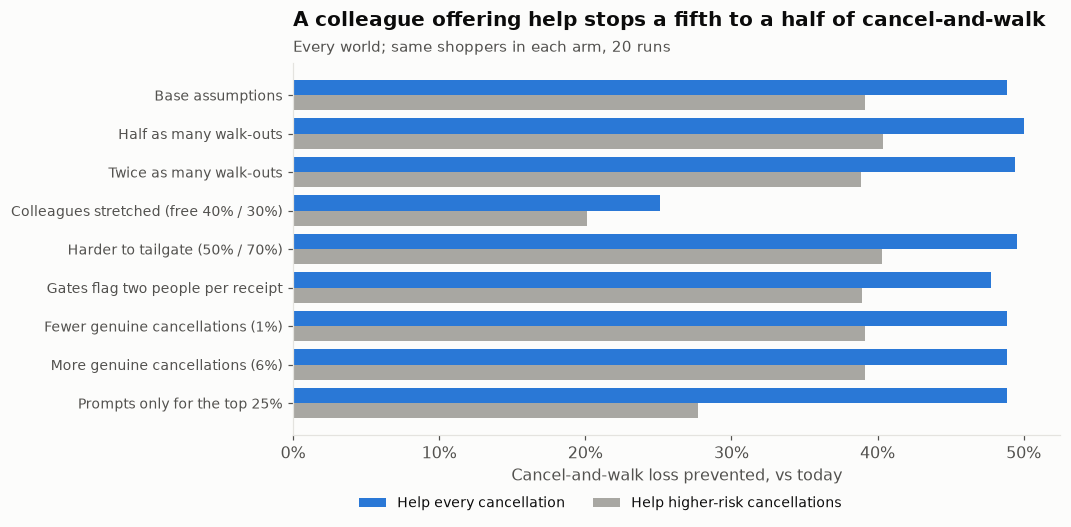

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.4))
worlds = list(today.index)
y = np.arange(len(worlds))
a = v13[v13.arm.str.contains('every')].set_index('world').loc[worlds, 'walk-out loss vs today']
b = v13[v13.arm.str.contains('higher')].set_index('world').loc[worlds, 'walk-out loss vs today']
ax.barh(y - 0.2, -a, 0.4, color=BLUE, label='Help every cancellation')
ax.barh(y + 0.2, -b, 0.4, color=GREY, label='Help higher-risk cancellations')
ax.set_yticks(y, worlds, fontsize=9)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(pct())
ax.set_xlabel('Cancel-and-walk loss prevented, vs today')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.4, -0.13), ncol=2, fontsize=9)
ax.grid(axis='y', visible=False)
ax.set_title('A colleague offering help stops a fifth to a half of cancel-and-walk')
subtitle(ax, 'Every world; same shoppers in each arm, 20 runs')
save(fig, '25_cancel_and_walk')
fig

**Reading it.**

- **Cancel-and-walk is a blind spot today**: about an eighth of all loss, and no rescan, model or
  loss estimate ever sees it.
- **A help prompt on cancellation halves it** when every cancellation gets one, and cuts it by
  about two-fifths when only the higher-risk half do. It stays effective in every world, and pays
  far more per colleague hour than rescans do ($75 per hour for v1.1), even counting the time
  resume saves on dead devices.
- **Most prompts go to genuine shoppers.** Only about one answered prompt in ten is a walk-out
  (one in eight with the risk score). That is why it must be *help*, worded and trained as service, with
  no reasons shown to the colleague, and why "help every cancellation" is also simply good service.
- **The risk score earns its keep when colleagues are stretched**: prompting only higher-risk
  cancellations keeps most of the effect for about half the colleague time.

## 3. Fairness of 'higher-risk' prompts

In [7]:
fair.round(3)

,attribute,lowest,highest,ratio
0,app or handset,0.488,0.489,0.999
1,new_smartshop_user,0.425,0.491,0.864
2,age_group,0.466,0.549,0.849
3,household_size,0.495,0.573,0.864
4,income_level,0.450,0.531,0.848


Among genuine cancellers, the share who would get a "higher-risk" prompt is similar across every
group (four-fifths ratios 0.85 or above), and in any case a prompt is an offer of help, not a
check. A device failure is never a risk signal, and cancelling is never used as one.

## Findings

| # | Finding | Implication |
|---|---|---|
| 1 | Cancel-and-walk is about an eighth of all loss and invisible to rescans and to the loss estimate | Count it separately (prompt and gate logs) next to the weighted loss estimate |
| 2 | A colleague prompt to help on every cancellation halves it; prompting only higher-risk cancellations cuts it by about two-fifths for about half the colleague time; both hold in every world | **v1.3**: help every cancellation when a colleague is near the exit, higher-risk only when stretched |
| 3 | About one answered prompt in ten is a walk-out (one in eight for higher-risk prompts) | It has to be help, never an accusation |
| 4 | Handing out the longest-charged handset and replacing worn batteries cuts dead handsets by 72–93% across simulated fleets, from the handset log alone | Cheap, and it is the store's problem to fix |
| 5 | Resume after a dead device saves about 10 customer hours and 3 colleague hours a period in the simulated chain | Never make a customer rescan for the store's failure |